In [3]:
import pandas as pd
import numpy as np 
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt


In [8]:
X , y_true =  make_blobs(n_samples=700,centers=5
                         ,cluster_std=.80,random_state=42)


In [514]:
X

array([[ 4.4487204 ,  1.24711875],
       [-7.95817553, -6.28549832],
       [ 1.78634049,  5.15964521],
       ...,
       [ 1.23631032,  3.98174504],
       [-6.31342564, -7.33008301],
       [ 1.97098956,  4.42446148]], shape=(700, 2))

In [515]:
df = pd.DataFrame(X,columns=['feature_1','feature_2'])

In [516]:
df

,feature_1,feature_2
0,4.448720,1.247119
1,-7.958176,-6.285498
2,1.786340,5.159645
3,1.086210,2.719867
4,5.942771,0.869089
...,...,...
695,4.263048,2.158810
696,1.718998,3.998587
697,1.236310,3.981745
698,-6.313426,-7.330083


In [517]:
scaler=StandardScaler()

In [518]:
X_Scale = scaler.fit_transform(df)

In [519]:
X_Scale

array([[ 1.31589872, -0.33753985],
       [-1.10821699, -1.67902212],
       [ 0.79571083,  0.35924121],
       ...,
       [ 0.68824344,  0.1494692 ],
       [-0.78685828, -1.865052  ],
       [ 0.83178841,  0.22831248]], shape=(700, 2))

###  Use elbomethod
<br>
wcss = inertia_

In [520]:
inertia = []
K_range = range(1,12)

In [521]:
for k in K_range:
    kmean = KMeans(n_clusters=k,random_state=42)
    kmean.fit(X_Scale)
    inertia.append(kmean.inertia_)

In [522]:
inertia

[1400.0000000000007,
 826.725130194179,
 165.57768727098022,
 60.709656544907446,
 30.18648635094297,
 28.16971361253914,
 25.865649051868623,
 24.391173135626687,
 23.983419606641,
 21.92815866540333,
 19.831177070792933]

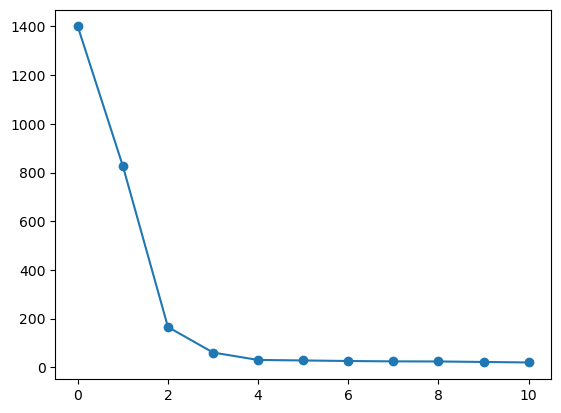

In [523]:
plt.plot( inertia,marker='o')
# this is elbo grpah
# and the best cluster point is K = 3

In [524]:
Kmeans_final = KMeans(n_clusters=5,random_state=42)

In [525]:
cluster_label = Kmeans_final.fit_predict(X_Scale)
# these 0 ,1 ,2 show the cluster group 

In [526]:
df['cluster'] = cluster_label

In [527]:
df.tail(7)

,feature_1,feature_2,cluster
693,-4.831560,-6.956958,2
694,4.947131,1.947014,4
695,4.263048,2.158810,4
696,1.718998,3.998587,1
697,1.236310,3.981745,1
698,-6.313426,-7.330083,2
699,1.970990,4.424461,1


<Axes: xlabel='feature_1', ylabel='feature_2'>

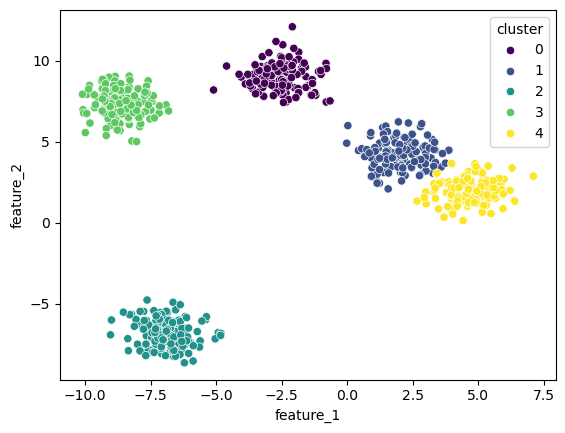

In [528]:
sns.scatterplot(x=df['feature_1'],
                y=df['feature_2'],
                hue = df['cluster'],
                palette='viridis'
)